<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and synthetic source](README.md)

# 01 · Daily distinct users do not add up to distinct users for a period

A report can be fully paged and correctly typed, yet still answer the wrong question when its rows are added together. We will ask the real GA4 worker for a daily report and a period-level report over the same event population. Event counts reconcile across dates; distinct-user counts depend on the requested grouping.

**Every event and user identifier in this notebook is explicitly synthetic.** A small local API companion implements exact distinct counting over the committed event fixture. It exercises the unchanged worker's HTTP, dynamic schema, pagination and type conversion. It is not a real Google property, a replay of Google responses, or a model of Google's identity/estimation systems. No credentials or visitor records are used.

## Choose a bounded property-calendar window

`START_DATE` is fixed at **2026-09-01**. `END_DATE` accepts **2026-09-03** (default) or **2026-09-05** (experiment). Both endpoints are inclusive property-calendar dates in the synthetic property's `America/New_York` time zone; they are not UTC timestamp bounds. This follows the [Data API date-range convention](https://developers.google.com/analytics/devguides/reporting/data/v1/rest/v1beta/DateRange).

Change only the end date to September 5. Predict that both events and period-level distinct users cannot decrease in this fixed fixture, while adding daily distinct counts will count some identifiers on more than one date. Restart Kernel → Run All after editing.

In [1]:
START_DATE = "2026-09-01"  # Fixed first calendar day, inclusive
END_DATE = "2026-09-03"  # Accepted: 2026-09-03 or 2026-09-05, inclusive

In [2]:
import hashlib
import json
import math
from pathlib import Path
from tempfile import TemporaryDirectory

import haybarn
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

from fixture_server import FixtureServer

assert START_DATE == "2026-09-01"
assert END_DATE in {"2026-09-03", "2026-09-05"}
fixture_path = Path("synthetic_events.json")
fixture = json.loads(fixture_path.read_text())
fixture_hash = hashlib.sha256(fixture_path.read_bytes()).hexdigest()
server = FixtureServer(fixture_path)
DATA_URL = server.url + "/data/v1beta"
ADMIN_URL = server.url + "/admin/v1beta"
expected = [e for e in fixture["events"] if START_DATE <= e["date"] <= END_DATE]
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {"figure.dpi": 125, "text.parse_math": False, "axes.spines.top": False, "axes.spines.right": False}
)


def prose(text):
    display(Markdown(text))


def finish(fig):
    fig.text(
        0.01,
        0.01,
        f"Source: SYNTHETIC notebook fixture · {START_DATE}–{END_DATE}, inclusive · America/New_York calendar dates · no visitor data",
        fontsize=8,
        color="#555555",
    )
    fig.tight_layout(rect=(0, 0.07, 1, 0.97))
    plt.show()


secret_directory = TemporaryDirectory(prefix="vgi-google-analytics-notebook-secrets-")
con = haybarn.connect(config={"secret_directory": secret_directory.name, "allow_persistent_secrets": False})
assert con.execute("SELECT count(*) FROM duckdb_secrets()").fetchall() == [(0,)]
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-google-analytics/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-google-analytics/notebooks/pyproject.toml.

## Attach the pinned worker and inspect metric types

The literal Git revision is remotely available and fetched by `uvx`; no checkout build is needed. SDK 0.51.0 is explicitly selected for protocol 3.3, matching Haybarn 2.0.0rc11. The source's locked SDK 0.50.0 speaks protocol 3.2 and fails this client handshake; no worker source or root lock was changed.

The documented API-URL options point only at this notebook's loopback server. `credentials 'secret'` prevents ADC/browser credential discovery. The visible token below is a fixed, non-secret fixture label that has no access to Google. `report_page_size=2` deliberately exercises pagination; it is not a report-row limit.

The metric names follow [Google's metric reference](https://developers.google.com/analytics/devguides/reporting/data/v1/api-schema#metrics). The local fixture defines `totalUsers` as distinct synthetic identifiers and `eventCount` as event records.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'ga4' AS ga4 (
    TYPE vgi,
    LOCATION 'uvx --from git+https://github.com/Query-farm/vgi-google-analytics@f0d25da5fe34e01bb8ec3fea04d7697ed0287db0 --with vgi-python==0.51.0 --with vgi-rpc==0.53.1 --with httpx==0.28.1 --with pyarrow==25.0.1 vgi-google-analytics',
    credentials 'secret',
    data_api_url '{{DATA_URL}}',
    admin_api_url '{{ADMIN_URL}}',
    report_page_size 2
);
CREATE TEMPORARY SECRET fixture_only (
    TYPE google_analytics,
    access_token 'synthetic-notebook-token'
);

,Success


In [4]:
%%sql metrics <<
SELECT api_name,column_type,description
FROM ga4.main.metrics('1001') ORDER BY api_name;

In [5]:
display(metrics)
assert set(metrics.api_name) == {"totalUsers", "eventCount"}
assert metrics.column_type.eq("BIGINT").all()
prose(
    f"**SYNTHETIC FIXTURE** · SHA-256 `{fixture_hash}`. The real worker exposes both fixture metrics as integer counts. Property 1001 is a local fixture identifier; it does not select a real Google property."
)

,api_name,column_type,description
0,eventCount,BIGINT,Synthetic event records
1,totalUsers,BIGINT,Distinct synthetic user IDs


**SYNTHETIC FIXTURE** · SHA-256 `019e005247ef48eb87bbc36fba6a1ba5b0a70ced77fc456139582169e628f920`. The real worker exposes both fixture metrics as integer counts. Property 1001 is a local fixture identifier; it does not select a real Google property.

## Retrieve the same population at two aggregation levels

The first request groups by date. The second requests no dimensions, so the source computes a single period total. Both use the same explicit date bounds and `max_rows=0` to consume every row the fixture advertises. Each report is materialized once before charts or summary queries.

`quality_columns=true` retains thresholding, other-row loss and sampling diagnostics. The fixture explicitly sets both flags false and contains no sampling metadata. The worker maps absent sampling metadata to 1.0; that default alone would not independently prove that a real report was unsampled.

In [6]:
%%sql
CREATE TABLE daily_report AS
SELECT * FROM ga4.main.report('1001',
    dimensions=>['date'],metrics=>['totalUsers','eventCount'],
    start_date=>'{{START_DATE}}',end_date=>'{{END_DATE}}',
    max_rows=>0,quality_columns=>true);
CREATE TABLE period_report AS
SELECT * FROM ga4.main.report('1001',
    dimensions=>[],metrics=>['totalUsers','eventCount'],
    start_date=>'{{START_DATE}}',end_date=>'{{END_DATE}}',
    max_rows=>0,quality_columns=>true);

,Count


In [7]:
%%sql daily <<
SELECT date,totalUsers AS daily_distinct_users,eventCount AS events
FROM daily_report ORDER BY date;

In [8]:
%%sql quality <<
SELECT 'Daily report' AS report,count(*) AS rows,
 bool_or(subject_to_thresholding) AS thresholding,
 bool_or(data_loss_from_other_row) AS other_row_loss,
 min(sampling_ratio) AS minimum_sampling_ratio
FROM daily_report
UNION ALL
SELECT 'Period report',count(*),bool_or(subject_to_thresholding),
 bool_or(data_loss_from_other_row),min(sampling_ratio) FROM period_report;

In [9]:
display(daily)
display(quality)
assert daily.date.is_unique and daily.date.notna().all()
assert len(daily) == (pd.Timestamp(END_DATE) - pd.Timestamp(START_DATE)).days + 1
assert daily.events.sum() == len(expected)
expected_users = len({e["user"] for e in expected})
period = con.execute("SELECT totalUsers,eventCount FROM period_report").fetchone()
assert period == (expected_users, len(expected))
for row in daily.itertuples():
    day_events = [e for e in expected if e["date"] == str(row.date.date())]
    assert row.daily_distinct_users == len({e["user"] for e in day_events})
    assert row.events == len(day_events)
assert not quality.thresholding.any() and not quality.other_row_loss.any()
assert quality.minimum_sampling_ratio.eq(1).all()
requests = [r for r in server.requests if r["kind"] == "report"]
daily_requests = [r for r in requests if r["dimensions"] == ["date"]]
assert [r["offset"] for r in daily_requests] == list(range(0, len(daily), 2))
assert len(daily_requests) == math.ceil(len(daily) / 2)
assert sum(r["rows"] for r in daily_requests) == len(daily)
assert len([r for r in requests if not r["dimensions"]]) == 1
display(
    pd.DataFrame(
        [{k: r[k] for k in ["dimensions", "offset", "limit", "rows", "total_rows"]} for r in requests]
    )
)
prose(
    f"The daily report returned **{len(daily)} dates across {len(daily_requests)} pages**, plus one period-level report. Independent fixture reconciliation confirms **{len(expected)} events** and **{expected_users} distinct synthetic users** in the selected range. Pagination completeness here is established against a finite known fixture, not inferred from a nonempty report."
)

,date,daily_distinct_users,events
0,2026-09-01,3,6
1,2026-09-02,4,9
2,2026-09-03,4,7


,report,rows,thresholding,other_row_loss,minimum_sampling_ratio
0,Daily report,3,False,False,1.0
1,Period report,1,False,False,1.0


,dimensions,offset,limit,rows,total_rows
0,[date],0,2,2,3
1,[date],2,2,1,3
2,[],0,2,1,1


The daily report returned **3 dates across 2 pages**, plus one period-level report. Independent fixture reconciliation confirms **22 events** and **6 distinct synthetic users** in the selected range. Pagination completeness here is established against a finite known fixture, not inferred from a nonempty report.

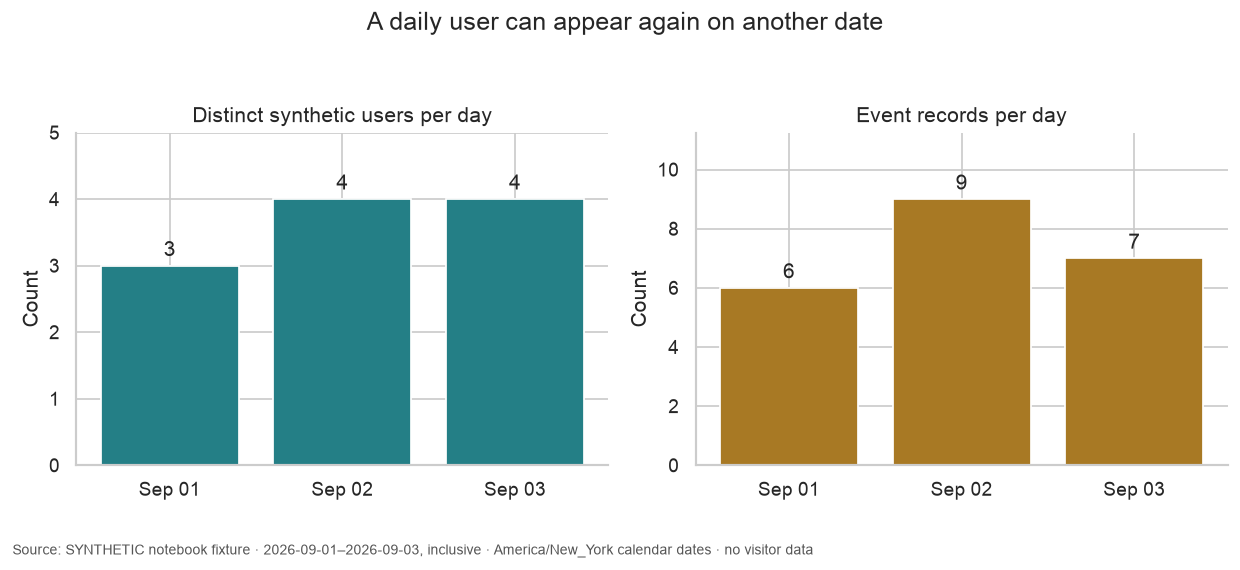

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.3))
labels = daily.date.dt.strftime("%b %d")
for ax, column, label, color in [
    (axes[0], "daily_distinct_users", "Distinct synthetic users per day", "#247f86"),
    (axes[1], "events", "Event records per day", "#a87924"),
]:
    bars = ax.bar(labels, daily[column], color=color)
    ax.bar_label(bars, padding=3, fmt="%.0f")
    ax.set(title=label, ylabel="Count", ylim=(0, max(1, daily[column].max() * 1.25)))
fig.suptitle("A daily user can appear again on another date", y=1.02)
finish(fig)

## Reconcile additive counts and expose repeated user-days

Summing `eventCount` over non-overlapping dates counts each synthetic event once. Summing `totalUsers` instead counts **user-days**: the same identifier contributes once on each active date. The period report deduplicates across the whole range. A user active on three dates contributes three user-days but one period user.

The next SQL computes both sums, then uses the period-level response as the denominator for an explicit comparison. It never substitutes zero for a missing report; the fixture checks above require the period report to exist.

The charts use independent vertical scales for user and event counts; compare the labeled quantities within each panel.

In [11]:
%%sql reconciliation <<
WITH daily_totals AS (
 SELECT sum(totalUsers) AS user_days,sum(eventCount) AS summed_events
 FROM daily_report
)
SELECT d.user_days,p.totalUsers AS period_distinct_users,
       d.user_days-p.totalUsers AS repeat_user_days,
       d.user_days/nullif(p.totalUsers,0) AS user_days_per_period_user,
       d.summed_events,p.eventCount AS period_events,
       d.summed_events-p.eventCount AS event_difference
FROM daily_totals d CROSS JOIN period_report p;

In [12]:
display(reconciliation)
r = reconciliation.iloc[0]
assert len(reconciliation) == 1 and r.event_difference == 0
assert r.user_days >= r.period_distinct_users > 0
assert r.user_days == sum(
    len({e["user"] for e in expected if e["date"] == day}) for day in {e["date"] for e in expected}
)
prose(
    f"Adding the daily user counts yields **{int(r.user_days)} user-days**, whereas the range report contains **{int(r.period_distinct_users)} distinct synthetic users**. The extra **{int(r.repeat_user_days)} user-days** come from identifiers appearing on additional dates, not additional people. The ratio is **{r.user_days_per_period_user:.2f} user-days per period user**. Both event calculations equal **{int(r.period_events)}**, an exact reconciliation for this fixture's disjoint date partitions."
)

,user_days,period_distinct_users,repeat_user_days,user_days_per_period_user,summed_events,period_events,event_difference
0,11.0,6,5.0,1.833333,22.0,22,0.0


Adding the daily user counts yields **11 user-days**, whereas the range report contains **6 distinct synthetic users**. The extra **5 user-days** come from identifiers appearing on additional dates, not additional people. The ratio is **1.83 user-days per period user**. Both event calculations equal **22**, an exact reconciliation for this fixture's disjoint date partitions.

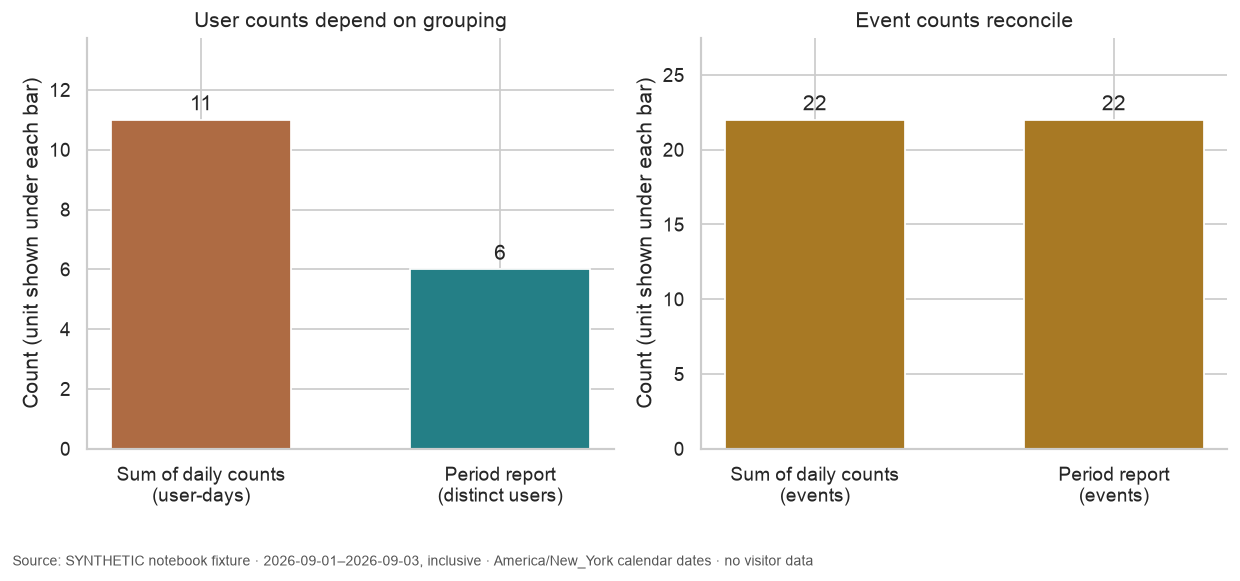

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.8))
for ax, values, labels, title, colors in [
    (
        axes[0],
        [r.user_days, r.period_distinct_users],
        ["Sum of daily counts\n(user-days)", "Period report\n(distinct users)"],
        "User counts depend on grouping",
        ["#ae6b43", "#247f86"],
    ),
    (
        axes[1],
        [r.summed_events, r.period_events],
        ["Sum of daily counts\n(events)", "Period report\n(events)"],
        "Event counts reconcile",
        ["#a87924", "#a87924"],
    ),
]:
    bars = ax.bar(labels, values, color=colors, width=0.6)
    ax.bar_label(bars, padding=3, fmt="%.0f")
    ax.set(title=title, ylabel="Count (unit shown under each bar)", ylim=(0, max(values) * 1.25))
finish(fig)

## Experiment: extend the same fixture through September 5

Change only `END_DATE` from **2026-09-03 to 2026-09-05** and run a separate copy. Compare the added dates, page offsets, period users, summed user-days and event reconciliation. Both source reports must still use identical inclusive date bounds. Restore **2026-09-03** for the default.

This experiment shows why the requested aggregation level belongs in the metric definition. It does not estimate real traffic, retention or conversion. The companion uses exact synthetic IDs and omits Google's reporting identity, estimation, privacy and thresholding behavior; an actual property requires its own data-quality and metric-compatibility review. Use a period-level report for the period question rather than assuming daily distinct counts are additive.

In [14]:
assert con.execute("SELECT count(*) FROM duckdb_secrets() WHERE persistent").fetchall() == [(0,)]
con.close()
server.close()
secret_directory.cleanup()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)